# Le pipeline ML : de la question à la surveillance

**Niveau :** débutant · **Durée :** 60–75 min · **Prérequis :** Python de base. Aucune connexion réseau ni GPU nécessaire.

**Question fil rouge.** À partir d'informations connues aujourd'hui, prédire si un client simulé quittera un service dans les 30 prochains jours. Toutes les données de cet exemple sont inventées et reproductibles.

À la fin, vous saurez :
1. nommer les étapes d'un projet ML et distinguer ce parcours d'un objet `sklearn.pipeline.Pipeline` ;
2. réserver train, validation et test à trois usages différents ;
3. ajuster imputation, échelle et encodage **uniquement sur l'entraînement** ;
4. faire une prédiction sur une nouvelle ligne et préciser ce qu'il faudrait surveiller ensuite.

Le parcours des étapes s'inspire de [GeeksforGeeks — Machine Learning Pipeline](https://www.geeksforgeeks.org/blogs/machine-learning-pipeline/) et de son [guide MLOps](https://www.geeksforgeeks.org/machine-learning/mlops-pipeline-implementing-efficient-machine-learning-operations/). Les schémas et l'exemple ci-dessous sont originaux.

<img src="images/01-ai-ml-dl-overview.png" alt="AI, Machine Learning et Deep Learning" width="760">

### Préparer son environnement

Le cours fonctionne sur CPU. Depuis la racine du dépôt, créez un environnement isolé puis installez les dépendances :

```bash
python -m venv .venv
.venv\Scripts\Activate.ps1  # Windows PowerShell
python -m pip install -e ".[dev]"
jupyter lab
```

L'environnement virtuel évite qu'une mise à jour d'un projet casse les autres projets. Git conserve l'historique des notebooks et GitHub facilite la revue des changements.

<img src="images/02-python-environment.png" alt="Installation de Python et préparation de l'environnement" width="760">

<img src="images/03-git-github-notebooks.png" alt="Git, GitHub et notebooks" width="760">

Le parcours initial n'exige pas de GPU : le CPU suffit pour les petits jeux de données et les modèles classiques. Un GPU devient utile quand les calculs matriciels d'un réseau de neurones et la taille des lots augmentent.

<img src="images/04-cpu-vs-gpu.png" alt="Comparaison entre CPU et GPU" width="760">

## 1. Deux sens du mot « pipeline »

Le **workflow du projet** part d'une question, collecte et examine les données, sépare les observations, entraîne et choisit un modèle, puis teste, sert et surveille ses prédictions. Il comprend des décisions humaines et des contrôles qui dépassent une classe Python.

L'objet **`Pipeline` de scikit-learn** enchaîne les transformations ajustées et l'estimateur. Lors de `fit`, il apprend les médianes, les catégories, l'échelle et les paramètres du modèle sur les données fournies. Lors de `predict`, il réutilise ces mêmes valeurs sans les recalculer.

Le schéma décrit le workflow. La boucle de retour représente une nouvelle étude des données lorsque la situation change ; elle ne signifie pas qu'un modèle se réentraîne tout seul.

### Vocabulaire et intuition mathématique

Une **feature** $x_j$ est une information disponible au moment de la prédiction. La **cible** $y$ est la valeur à prédire ; ici $y \in \{0,1\}$. Un modèle est une fonction paramétrée $\hat{y}=f_\theta(x)$. L'entraînement cherche les paramètres $\theta$ qui réduisent une fonction de perte.

Pour une classification logistique, la probabilité de la classe 1 est :

$$p(y=1\mid x)=\sigma(w^T x+b)=\frac{1}{1+e^{-(w^T x+b)}}.$$

La perte logistique moyenne sur $n$ observations est :

$$J(w,b)=-\frac{1}{n}\sum_{i=1}^{n} \left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].$$

Le code utilise scikit-learn pour optimiser cette perte ; les formules expliquent ce que le modèle ajuste.

<img src="images/05-ml-lifecycle.png" alt="Cycle général d'un projet Machine Learning" width="760">

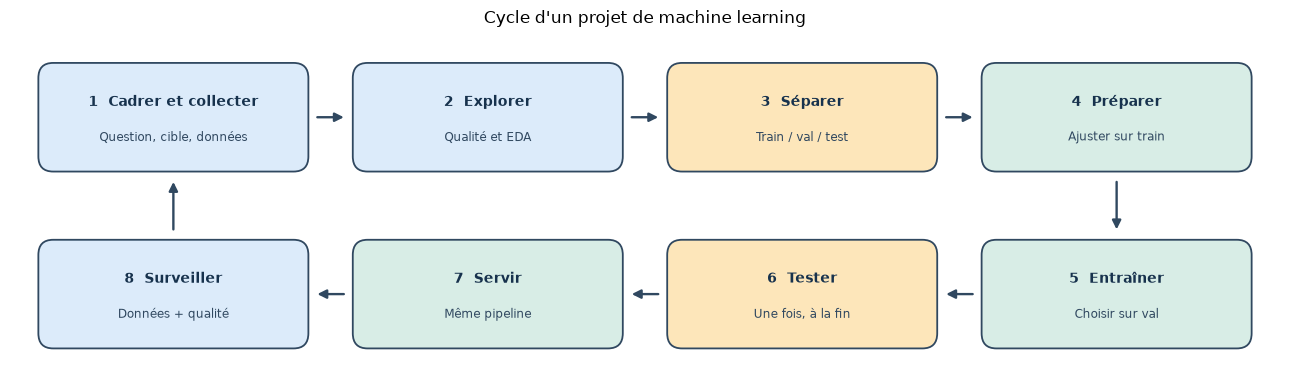

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

top_x = [0.2, 2.75, 5.3, 7.85]
bottom_x = [7.85, 5.3, 2.75, 0.2]
top_y, bottom_y = 1.75, 0.35
stages = [
    (top_x[0], top_y, "1  Cadrer et collecter", "Question, cible, données", "#DCEBFA"),
    (top_x[1], top_y, "2  Explorer", "Qualité et EDA", "#DCEBFA"),
    (top_x[2], top_y, "3  Séparer", "Train / val / test", "#FDE6BA"),
    (top_x[3], top_y, "4  Préparer", "Ajuster sur train", "#D8EDE6"),
    (bottom_x[0], bottom_y, "5  Entraîner", "Choisir sur val", "#D8EDE6"),
    (bottom_x[1], bottom_y, "6  Tester", "Une fois, à la fin", "#FDE6BA"),
    (bottom_x[2], bottom_y, "7  Servir", "Même pipeline", "#D8EDE6"),
    (bottom_x[3], bottom_y, "8  Surveiller", "Données + qualité", "#DCEBFA"),
]

fig, ax = plt.subplots(figsize=(13, 4))
for x, y, title, subtitle, fill in stages:
    ax.add_patch(FancyBboxPatch(
        (x, y), 2.15, 0.82,
        boxstyle="round,pad=0.02,rounding_size=0.12",
        facecolor=fill, edgecolor="#304860", linewidth=1.3,
    ))
    ax.text(x + 1.075, y + 0.53, title, ha="center", va="center",
            fontsize=10, fontweight="bold", color="#17324D")
    ax.text(x + 1.075, y + 0.25, subtitle, ha="center", va="center",
            fontsize=8.5, color="#304860")

arrow = dict(arrowstyle="-|>", color="#304860", lw=1.7, mutation_scale=13)
for left, right in zip(top_x[:-1], top_x[1:]):
    ax.annotate("", xy=(right - 0.07, top_y + 0.41),
                xytext=(left + 2.22, top_y + 0.41), arrowprops=arrow)
ax.annotate("", xy=(bottom_x[0] + 1.075, bottom_y + 0.9),
            xytext=(top_x[-1] + 1.075, top_y - 0.08), arrowprops=arrow)
for right, left in zip(bottom_x[:-1], bottom_x[1:]):
    ax.annotate("", xy=(left + 2.22, bottom_y + 0.41),
                xytext=(right - 0.07, bottom_y + 0.41), arrowprops=arrow)
ax.annotate("", xy=(top_x[0] + 1.075, top_y - 0.08),
            xytext=(bottom_x[-1] + 1.075, bottom_y + 0.9), arrowprops=arrow)

ax.set(xlim=(-0.05, 10.25), ylim=(0.08, 2.84),
       title="Cycle d'un projet de machine learning")
ax.axis("off")
plt.tight_layout()
plt.show()

**Lecture du schéma.** La séparation arrive avant tout apprentissage statistique du prétraitement. Le test reste fermé pendant le choix du modèle. La prédiction d'une nouvelle observation repasse par le même prétraitement que l'entraînement. La surveillance peut révéler un changement des données ou une baisse de qualité et déclencher une nouvelle itération.

## 2. Collecter et vérifier les données

Nous générons 240 clients fictifs. `anciennete_mois`, `visites_30j` et `canal` sont connus au moment de la prédiction ; `depart_30j` est la cible future. Quelques anciennetés sont volontairement absentes. Une vraie collecte demanderait aussi de vérifier consentement, définition de l'événement, doublons et décalage temporel entre variables et cible.

### Contrôle qualité avant le modèle

Avant de choisir un algorithme, vérifier quatre points : chaque ligne représente une unité claire ; les variables existaient avant l'événement ; la cible est définie sans ambiguïté ; les valeurs manquantes ont une cause compréhensible. Une variable très prédictive mais disponible seulement après le départ serait une **fuite de cible**.

In [ ]:
# NumPy sert ici à générer des valeurs reproductibles ; Pandas organise la table.
import numpy as np
import pandas as pd

# Une graine fixe permet à un autre apprenant d'obtenir les mêmes résultats.
rng = np.random.default_rng(17)
n = 240
anciennete = rng.integers(1, 61, n).astype(float)
visites = rng.poisson(3.2, n)
canal = rng.choice(["web", "boutique", "telephone"], size=n, p=[0.55, 0.25, 0.20])
logit = -0.9 - 0.035 * anciennete + 0.35 * visites + 0.55 * (canal == "telephone")
probabilite = 1 / (1 + np.exp(-logit))
y = pd.Series(rng.binomial(1, probabilite), name="depart_30j")
X = pd.DataFrame({
    "anciennete_mois": anciennete,
    "visites_30j": visites,
    "canal": canal,
})
X.loc[rng.choice(n, size=20, replace=False), "anciennete_mois"] = np.nan
print("Dimensions :", X.shape, "| part de départs :", round(y.mean(), 3))
print("Valeurs manquantes par colonne :")
print(X.isna().sum())
print("Exemple de lignes :")
print(X.head(3))

## 3. Séparer avant d'apprendre les transformations

Ici, **60 %** des lignes servent à apprendre les paramètres, **20 %** à choisir entre deux réglages et **20 %** au score final. La stratification conserve approximativement la proportion des classes. Elle convient à cet exemple indépendant ; un problème temporel ou avec plusieurs lignes par client demanderait une séparation adaptée.

La médiane d'imputation et la moyenne d'échelle ne doivent pas être calculées sur l'ensemble des 240 lignes. Cela donnerait au modèle des informations venues de la validation ou du test. La [documentation scikit-learn sur les fuites de données](https://scikit-learn.org/stable/common_pitfalls) détaille cette règle.

<img src="images/06-train-validation-test.png" alt="Rôles des ensembles train, validation et test" width="760">

Si l'on note $D$ le jeu complet, on construit ici $D=D_{train}\cup D_{val}\cup D_{test}$, avec des sous-ensembles disjoints. Le train apprend les paramètres, la validation aide à choisir, et le test donne une estimation finale après le choix.

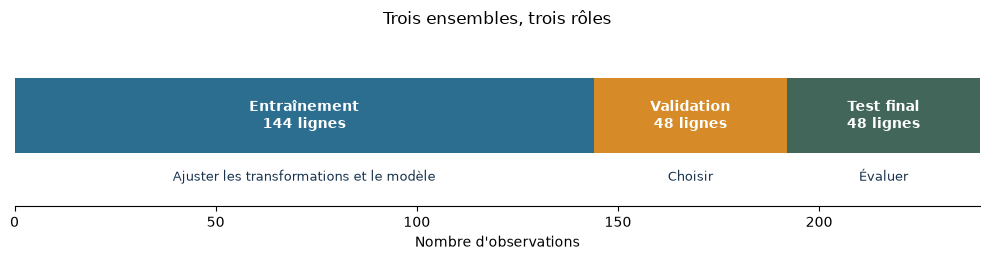

In [ ]:
# On sépare avant tout fit de l'imputer, du scaler ou de l'encodeur.
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=17
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    stratify=y_train_val, random_state=17
)
parts = [
    ("Entraînement", len(X_train), "#2C6E8F"),
    ("Validation", len(X_val), "#D68A28"),
    ("Test final", len(X_test), "#42665A"),
]
fig, ax = plt.subplots(figsize=(10, 2.7))
left = 0
for label, count, color in parts:
    ax.barh(0, count, left=left, height=0.5, color=color)
    ax.text(left + count / 2, 0, f"{label}\n{count} lignes",
            ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += count
ax.text(len(X_train) / 2, -0.43, "Ajuster les transformations et le modèle",
        ha="center", fontsize=9, color="#17324D")
ax.text(len(X_train) + len(X_val) / 2, -0.43, "Choisir",
        ha="center", fontsize=9, color="#17324D")
ax.text(len(X_train) + len(X_val) + len(X_test) / 2, -0.43, "Évaluer",
        ha="center", fontsize=9, color="#17324D")
ax.set(xlim=(0, len(X)), ylim=(-0.6, 0.55),
       xlabel="Nombre d'observations",
       title="Trois ensembles, trois rôles")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture de la figure.** Les tailles exactes sont 144, 48 et 48 lignes. Le bloc test est gardé à part jusqu'après le choix du réglage. Les pourcentages sont un exemple pédagogique, pas une règle universelle : la taille et le type de séparation dépendent du problème.

## 4. Transformer les colonnes et entraîner

`ColumnTransformer` applique une branche aux nombres et une autre aux catégories. `Pipeline` relie ces branches à une régression logistique. Les deux objets sont **ajustés par `fit(X_train, y_train)`** : la validation et le test passent ensuite seulement par `predict`.

Nous comparons deux valeurs de `C` avec la **balanced accuracy**, utile ici car les deux classes ne sont pas nécessairement égales. La validation choisit un réglage ; elle n'est pas une estimation finale indépendante. Pour comparer davantage de réglages, utiliser une validation croisée sur l'entraînement, en gardant toujours le test final à part.

Pour une classification binaire, la balanced accuracy moyenne les rappels des deux classes :

$$\operatorname{BA}=\frac{1}{2}\left(\frac{TP}{TP+FN}+\frac{TN}{TN+FP}\right).$$

Le paramètre `C` est l'inverse de la force de régularisation dans `LogisticRegression`. Un `C` petit pénalise davantage les coefficients complexes ; il ne faut pas choisir sa valeur en regardant le test.

<img src="images/07-training-inference.png" alt="Entraînement et prédiction : mêmes transformations, usages différents" width="760">

In [ ]:
# Chaque branche apprend ses propres paramètres uniquement dans Pipeline.fit.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construire_pipeline(c):
    numerique = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("echelle", StandardScaler()),
    ])
    categoriel = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    preparation = ColumnTransformer([
        ("num", numerique, ["anciennete_mois", "visites_30j"]),
        ("cat", categoriel, ["canal"]),
    ])
    return Pipeline([
        ("preparation", preparation),
        ("modele", LogisticRegression(C=c, max_iter=1000)),
    ])

scores_validation = {}
for c in [0.3, 3.0]:
    candidat = construire_pipeline(c)
    candidat.fit(X_train, y_train)
    scores_validation[c] = balanced_accuracy_score(y_val, candidat.predict(X_val))
print("Balanced accuracy sur validation :", scores_validation)
meilleur_c = max(scores_validation, key=scores_validation.get)
print("Réglage retenu : C =", meilleur_c)

## 5. Un seul test final

Après le choix, nous réajustons un nouveau pipeline sur l'union entraînement + validation. **C'est seulement maintenant** que nous calculons le score du test. Changer encore le modèle en fonction de ce score ferait perdre au test son rôle d'évaluation indépendante.

In [ ]:
# Après le choix de C, on peut réunir train et validation pour l'ajustement final.
# Le test reste intact jusqu'à cette mesure unique.
X_developpement = pd.concat([X_train, X_val])
y_developpement = pd.concat([y_train, y_val])
pipeline_final = construire_pipeline(meilleur_c)
pipeline_final.fit(X_developpement, y_developpement)
pred_test = pipeline_final.predict(X_test)
score_test = balanced_accuracy_score(y_test, pred_test)
print(f"Balanced accuracy finale sur {len(X_test)} clients inédits : {score_test:.3f}")

## 6. Servir puis surveiller

Le bloc `predict_proba` ci-dessous **simule l'inférence** sur deux nouveaux clients. Le même objet applique les imputations, l'échelle et l'encodage appris pendant `fit`. Dans un service réel, on emballerait cet objet avec son environnement, une API et des tests.

Pendant `fit`, le modèle reçoit des exemples avec labels et apprend $\theta$. Pendant `predict`, il reçoit seulement de nouvelles features et calcule $\hat{y}=f_\theta(x)$. Aucune nouvelle moyenne, médiane ou catégorie ne doit être apprise à ce moment-là.

**Rappel :** le schéma entraînement/inférence est présenté une seule fois dans la section précédente.
Sans labels récents, on peut seulement surveiller les **entrées** : leur disponibilité et leur distribution. Une hausse des visites moyennes ne prouve pas une baisse de qualité prédictive. Il faut recueillir les vrais départs plus tard pour mesurer la performance, puis décider si un nouvel entraînement est nécessaire.

In [ ]:
# En production, ces lignes arriveraient via une API ou un traitement batch.
nouveaux_clients = pd.DataFrame({
    "anciennete_mois": [12.0, np.nan],
    "visites_30j": [2, 7],
    "canal": ["web", "telephone"],
})
probabilites_depart = pipeline_final.predict_proba(nouveaux_clients)[:, 1]
print("Probabilités illustratives de départ :", probabilites_depart.round(3))

visites_recentes = np.random.default_rng(23).poisson(6.0, size=80)
print(
    "Visites moyennes : développement =",
    round(X_developpement["visites_30j"].mean(), 2),
    "| lot récent simulé =",
    round(visites_recentes.mean(), 2),
)

## À retenir et à essayer

- **Workflow ML** : décider quoi prédire, avec quelles données et comment vérifier le résultat jusqu'à la surveillance.
- **`Pipeline` scikit-learn** : enchaîner dans le code les transformations apprises et le modèle ; le `fit` voit uniquement les données autorisées.
- **Train / validation / test** : apprendre / choisir / évaluer une fois. Pour des observations liées dans le temps ou par client, adapter la séparation.
- **Surveillance** : suivre les données immédiatement et la qualité dès que les vrais labels deviennent disponibles.

**Expérience.** Remplacez `C=0.3` et `C=3.0` par deux autres valeurs ; relancez jusqu'à la validation, choisissez, puis exécutez le test final une seule fois. Essayez un nouveau client dont `canal` vaut `application` : `handle_unknown="ignore"` permet la prédiction, mais une nouvelle catégorie fréquente mérite une enquête.

**Pour approfondir :** [Pipeline et ColumnTransformer sur GeeksforGeeks](https://www.geeksforgeeks.org/machine-learning/prediction-using-columntransformer-onehotencoder-and-pipeline/), [guide officiel scikit-learn sur les estimateurs composites](https://scikit-learn.org/stable/modules/compose.html) et [module 03 du présent dépôt](../03-data-preprocessing/README.md). Les figures de cette leçon sont créées par son code et n'utilisent aucune image GeeksforGeeks.